<a href="https://colab.research.google.com/github/MoSibai2/small-business-data-analysis/blob/main/small_business_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

data = {
    "order_id": [1001, 1002, 1003, 1004, 1005, 1006,
                 1007, 1008, 1009, 1010, 1011, 1012],
    "order_date": [
        "2026-01-02", "2026-01-03", "2026-01-03",
        "2026-01-05", "2026-01-07", "2026-01-08",
        "2026-01-10", "2026-01-12", "2026-01-13",
        "2026-01-15", "2026-01-17", "2026-01-18"
    ],
    "product": [
        "Laptop", "Mouse", "Keyboard", "Monitor",
        "Mouse", "Laptop", "Keyboard", "Monitor",
        "Headphones", "Mouse", "Laptop", "Keyboard"
    ],
    "category": [
        "Electronics", "Accessories", "Accessories",
        "Electronics", "Accessories", "Electronics",
        "Accessories", "Electronics", "Accessories",
        "Accessories", "Electronics", "Accessories"
    ],
    "quantity": [1, 2, 1, 1, 3, 1, 2, 1, 2, 1, 1, 2],
    "unit_price": [15000, 350, 800, 6000, 350, 15000,
                   800, 6000, 1200, 350, 15000, 800],
    "customer_city": [
        "Cairo", "Giza", "Alexandria", "Cairo",
        "Giza", "Cairo", None, "Alexandria",
        "Cairo", "Giza", "Cairo", "Alexandria"
    ],
    "payment_method": [
        "Card", "Cash", "Card", "Card",
        "Cash", "Card", "Cash", None,
        "Card", "Cash", "Card", "Cash"
    ]
}

df = pd.DataFrame(data)

# Add intentional data quality issues
df.loc[4, "unit_price"] = -350
df.loc[8, "quantity"] = None

# Add a duplicate row
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

print("Dataset Shape:", df.shape)
display(df)

Dataset Shape: (13, 8)


,order_id,order_date,product,category,quantity,unit_price,customer_city,payment_method
0,1001,2026-01-02,Laptop,Electronics,1.0,15000,Cairo,Card
1,1002,2026-01-03,Mouse,Accessories,2.0,350,Giza,Cash
2,1003,2026-01-03,Keyboard,Accessories,1.0,800,Alexandria,Card
3,1004,2026-01-05,Monitor,Electronics,1.0,6000,Cairo,Card
4,1005,2026-01-07,Mouse,Accessories,3.0,-350,Giza,Cash
5,1006,2026-01-08,Laptop,Electronics,1.0,15000,Cairo,Card
6,1007,2026-01-10,Keyboard,Accessories,2.0,800,None,Cash
7,1008,2026-01-12,Monitor,Electronics,1.0,6000,Alexandria,None
8,1009,2026-01-13,Headphones,Accessories,NaN,1200,Cairo,Card
9,1010,2026-01-15,Mouse,Accessories,1.0,350,Giza,Cash


In [ ]:
# Basic dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        13 non-null     int64  
 1   order_date      13 non-null     object 
 2   product         13 non-null     object 
 3   category        13 non-null     object 
 4   quantity        12 non-null     float64
 5   unit_price      13 non-null     int64  
 6   customer_city   12 non-null     object 
 7   payment_method  12 non-null     object 
dtypes: float64(1), int64(2), object(5)
memory usage: 964.0+ bytes

Missing Values:
order_id          0
order_date        0
product           0
category          0
quantity          1
unit_price        0
customer_city     1
payment_method    1
dtype: int64

Duplicate Rows:
1

Statistical Summary:


,order_id,order_date,product,category,quantity,unit_price,customer_city,payment_method
count,13.000000,13,13,13,12.000000,13.000000,12,12
unique,NaN,11,5,2,NaN,NaN,3,2
top,NaN,2026-01-02,Laptop,Accessories,NaN,NaN,Cairo,Card
freq,NaN,2,4,7,NaN,NaN,6,7
mean,1006.076923,NaN,NaN,NaN,1.416667,5842.307692,NaN,NaN
std,3.774068,NaN,NaN,NaN,0.668558,6658.354594,NaN,NaN
min,1001.000000,NaN,NaN,NaN,1.000000,-350.000000,NaN,NaN
25%,1003.000000,NaN,NaN,NaN,1.000000,800.000000,NaN,NaN
50%,1006.000000,NaN,NaN,NaN,1.000000,1200.000000,NaN,NaN
75%,1009.000000,NaN,NaN,NaN,2.000000,15000.000000,NaN,NaN


In [ ]:
# Create a backup of the original dataset
df_raw = df.copy()

# Remove duplicate rows
df = df.drop_duplicates()

print("Original rows:", len(df_raw))
print("Rows after removing duplicates:", len(df))
print("Duplicates remaining:", df.duplicated().sum())

Original rows: 13
Rows after removing duplicates: 12
Duplicates remaining: 0


In [ ]:
# Handle missing categorical values
df["customer_city"] = df["customer_city"].fillna("Unknown")
df["payment_method"] = df["payment_method"].fillna("Unknown")

# Check missing values after treatment
print("Missing Values After Treatment:")
print(df.isnull().sum())

print("\nUpdated Dataset:")
display(df)

Missing Values After Treatment:
order_id          0
order_date        0
product           0
category          0
quantity          1
unit_price        0
customer_city     0
payment_method    0
dtype: int64

Updated Dataset:


,order_id,order_date,product,category,quantity,unit_price,customer_city,payment_method
0,1001,2026-01-02,Laptop,Electronics,1.0,15000,Cairo,Card
1,1002,2026-01-03,Mouse,Accessories,2.0,350,Giza,Cash
2,1003,2026-01-03,Keyboard,Accessories,1.0,800,Alexandria,Card
3,1004,2026-01-05,Monitor,Electronics,1.0,6000,Cairo,Card
4,1005,2026-01-07,Mouse,Accessories,3.0,-350,Giza,Cash
5,1006,2026-01-08,Laptop,Electronics,1.0,15000,Cairo,Card
6,1007,2026-01-10,Keyboard,Accessories,2.0,800,Unknown,Cash
7,1008,2026-01-12,Monitor,Electronics,1.0,6000,Alexandria,Unknown
8,1009,2026-01-13,Headphones,Accessories,NaN,1200,Cairo,Card
9,1010,2026-01-15,Mouse,Accessories,1.0,350,Giza,Cash


In [ ]:
# Identify invalid prices
invalid_prices = df[df["unit_price"] <= 0]

print("Invalid Price Records:")
display(invalid_prices)

print("Number of invalid price records:", len(invalid_prices))

Invalid Price Records:


,order_id,order_date,product,category,quantity,unit_price,customer_city,payment_method
4,1005,2026-01-07,Mouse,Accessories,3.0,-350,Giza,Cash


Number of invalid price records: 1


In [ ]:
# Create a dataset containing only valid prices
df_valid = df[df["unit_price"] > 0].copy()

print("Rows before filtering:", len(df))
print("Rows after filtering:", len(df_valid))
print("Invalid price records excluded:", len(df) - len(df_valid))

display(df_valid)

Rows before filtering: 12
Rows after filtering: 11
Invalid price records excluded: 1


,order_id,order_date,product,category,quantity,unit_price,customer_city,payment_method
0,1001,2026-01-02,Laptop,Electronics,1.0,15000,Cairo,Card
1,1002,2026-01-03,Mouse,Accessories,2.0,350,Giza,Cash
2,1003,2026-01-03,Keyboard,Accessories,1.0,800,Alexandria,Card
3,1004,2026-01-05,Monitor,Electronics,1.0,6000,Cairo,Card
5,1006,2026-01-08,Laptop,Electronics,1.0,15000,Cairo,Card
6,1007,2026-01-10,Keyboard,Accessories,2.0,800,Unknown,Cash
7,1008,2026-01-12,Monitor,Electronics,1.0,6000,Alexandria,Unknown
8,1009,2026-01-13,Headphones,Accessories,NaN,1200,Cairo,Card
9,1010,2026-01-15,Mouse,Accessories,1.0,350,Giza,Cash
10,1011,2026-01-17,Laptop,Electronics,1.0,15000,Cairo,Card


In [ ]:
# Convert order_date to datetime
df_valid["order_date"] = pd.to_datetime(
    df_valid["order_date"],
    errors="coerce"
)

# Verify the conversion
print("Updated Data Types:")
print(df_valid.dtypes)

print("\nInvalid Dates:", df_valid["order_date"].isna().sum())

Updated Data Types:
order_id                   int64
order_date        datetime64[ns]
product                   object
category                  object
quantity                 float64
unit_price                 int64
customer_city             object
payment_method            object
dtype: object

Invalid Dates: 0


In [ ]:
# Separate records with missing quantities
missing_quantity = df_valid[df_valid["quantity"].isna()].copy()

# Keep only records with valid quantities
df_analysis = df_valid[df_valid["quantity"].notna()].copy()

print("Records before quantity filtering:", len(df_valid))
print("Records with missing quantity:", len(missing_quantity))
print("Records ready for sales analysis:", len(df_analysis))

print("\nRecords requiring review:")
display(missing_quantity)

Records before quantity filtering: 11
Records with missing quantity: 1
Records ready for sales analysis: 10

Records requiring review:


,order_id,order_date,product,category,quantity,unit_price,customer_city,payment_method
8,1009,2026-01-13,Headphones,Accessories,NaN,1200,Cairo,Card


In [ ]:
# Calculate total revenue for each order
df_analysis["total_revenue"] = (
    df_analysis["quantity"] * df_analysis["unit_price"]
)

# Display updated dataset
display(df_analysis)

# Calculate overall revenue
total_revenue = df_analysis["total_revenue"].sum()

print(f"Total Revenue: {total_revenue:,.2f} EGP")

,order_id,order_date,product,category,quantity,unit_price,customer_city,payment_method,total_revenue
0,1001,2026-01-02,Laptop,Electronics,1.0,15000,Cairo,Card,15000.0
1,1002,2026-01-03,Mouse,Accessories,2.0,350,Giza,Cash,700.0
2,1003,2026-01-03,Keyboard,Accessories,1.0,800,Alexandria,Card,800.0
3,1004,2026-01-05,Monitor,Electronics,1.0,6000,Cairo,Card,6000.0
5,1006,2026-01-08,Laptop,Electronics,1.0,15000,Cairo,Card,15000.0
6,1007,2026-01-10,Keyboard,Accessories,2.0,800,Unknown,Cash,1600.0
7,1008,2026-01-12,Monitor,Electronics,1.0,6000,Alexandria,Unknown,6000.0
9,1010,2026-01-15,Mouse,Accessories,1.0,350,Giza,Cash,350.0
10,1011,2026-01-17,Laptop,Electronics,1.0,15000,Cairo,Card,15000.0
11,1012,2026-01-18,Keyboard,Accessories,2.0,800,Alexandria,Cash,1600.0


Total Revenue: 62,050.00 EGP


In [ ]:
# Analyze product performance
product_performance = (
    df_analysis
    .groupby("product")
    .agg(
        total_revenue=("total_revenue", "sum"),
        total_quantity=("quantity", "sum"),
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

display(product_performance)

,total_revenue,total_quantity,total_orders
product,,,
Laptop,45000.0,3.0,3
Monitor,12000.0,2.0,2
Keyboard,4000.0,5.0,3
Mouse,1050.0,3.0,2


In [ ]:
# Analyze category performance
category_performance = (
    df_analysis
    .groupby("category")
    .agg(
        total_revenue=("total_revenue", "sum"),
        total_quantity=("quantity", "sum"),
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

display(category_performance)

,total_revenue,total_quantity,total_orders
category,,,
Electronics,57000.0,5.0,5
Accessories,5050.0,8.0,5


In [ ]:
# Analyze sales by customer city
city_performance = (
    df_analysis
    .groupby("customer_city")
    .agg(
        total_revenue=("total_revenue", "sum"),
        total_quantity=("quantity", "sum"),
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

display(city_performance)

,total_revenue,total_quantity,total_orders
customer_city,,,
Cairo,51000.0,4.0,4
Alexandria,8400.0,4.0,3
Unknown,1600.0,2.0,1
Giza,1050.0,3.0,2


In [ ]:
# Analyze payment methods
payment_performance = (
    df_analysis
    .groupby("payment_method")
    .agg(
        total_revenue=("total_revenue", "sum"),
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

# Calculate revenue percentage
payment_performance["revenue_percentage"] = (
    payment_performance["total_revenue"]
    / df_analysis["total_revenue"].sum()
    * 100
)

display(payment_performance.round(2))

,total_revenue,total_orders,revenue_percentage
payment_method,,,
Card,51800.0,5,83.48
Unknown,6000.0,1,9.67
Cash,4250.0,4,6.85


In [ ]:
# Extract month from order date
df_analysis["order_month"] = (
    df_analysis["order_date"].dt.to_period("M").astype(str)
)

display(df_analysis[["order_id", "order_date", "order_month", "total_revenue"]])

,order_id,order_date,order_month,total_revenue
0,1001,2026-01-02,2026-01,15000.0
1,1002,2026-01-03,2026-01,700.0
2,1003,2026-01-03,2026-01,800.0
3,1004,2026-01-05,2026-01,6000.0
5,1006,2026-01-08,2026-01,15000.0
6,1007,2026-01-10,2026-01,1600.0
7,1008,2026-01-12,2026-01,6000.0
9,1010,2026-01-15,2026-01,350.0
10,1011,2026-01-17,2026-01,15000.0
11,1012,2026-01-18,2026-01,1600.0


In [ ]:
# Analyze monthly sales performance
monthly_performance = df_analysis.groupby("order_month").agg(
    total_revenue=("total_revenue", "sum"),
    total_orders=("order_id", "nunique"),
    total_quantity=("quantity", "sum")
).sort_index()

display(monthly_performance)

,total_revenue,total_orders,total_quantity
order_month,,,
2026-01,62050.0,10,13.0


In [ ]:
# Calculate Average Order Value
total_orders = df_analysis["order_id"].nunique()
total_revenue = df_analysis["total_revenue"].sum()

average_order_value = total_revenue / total_orders

print(f"Total Orders: {total_orders}")
print(f"Total Revenue: {total_revenue:,.2f} EGP")
print(f"Average Order Value: {average_order_value:,.2f} EGP")

Total Orders: 10
Total Revenue: 62,050.00 EGP
Average Order Value: 6,205.00 EGP


In [ ]:
# Calculate key business metrics
total_revenue = df_analysis["total_revenue"].sum()
total_orders = df_analysis["order_id"].nunique()
total_items = df_analysis["quantity"].sum()
average_order_value = total_revenue / total_orders

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Total Items Sold",
        "Average Order Value"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_items,
        average_order_value
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Revenue,62050.0
1,Total Orders,10.0
2,Total Items Sold,13.0
3,Average Order Value,6205.0


In [ ]:
# Final data quality checks
print("Duplicate Rows:", df_analysis.duplicated().sum())
print("Missing Values:")
print(df_analysis.isnull().sum())

print("\nNegative Prices:", (df_analysis["unit_price"] <= 0).sum())
print("Invalid Quantities:", (df_analysis["quantity"] <= 0).sum())

Duplicate Rows: 0
Missing Values:
order_id          0
order_date        0
product           0
category          0
quantity          0
unit_price        0
customer_city     0
payment_method    0
total_revenue     0
order_month       0
dtype: int64

Negative Prices: 0
Invalid Quantities: 0


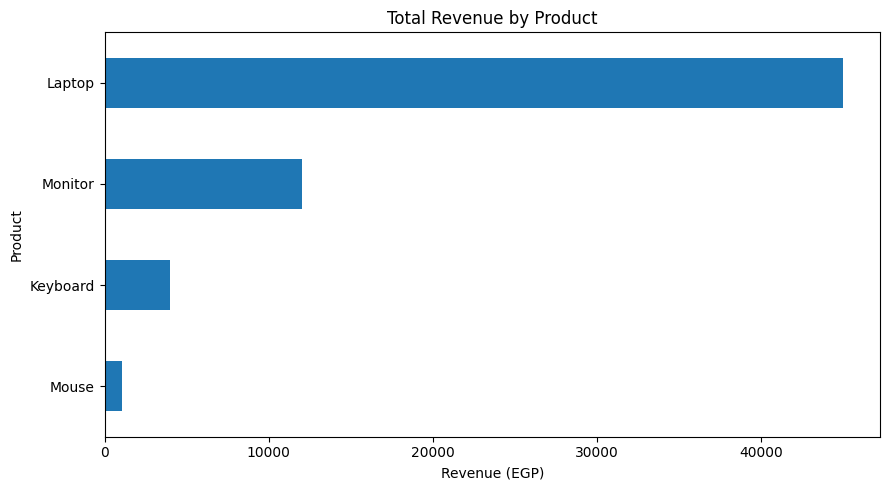

In [ ]:
import matplotlib.pyplot as plt

product_performance["total_revenue"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Total Revenue by Product",
    xlabel="Revenue (EGP)",
    ylabel="Product"
)

plt.tight_layout()
plt.show()

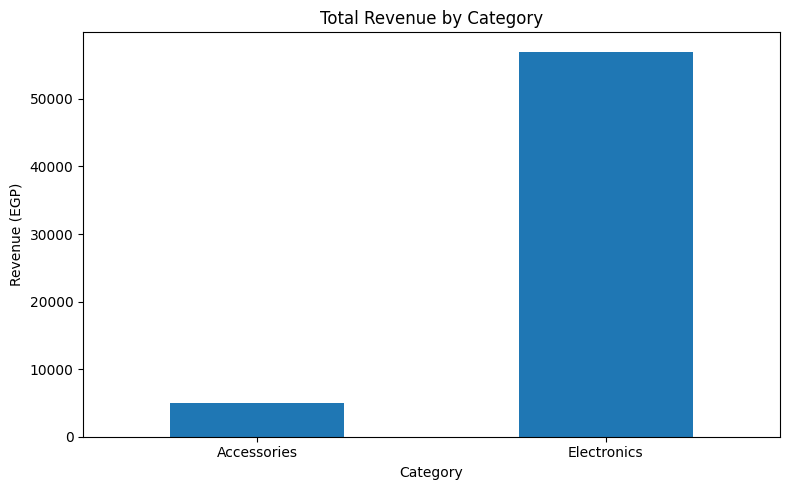

In [ ]:
category_performance["total_revenue"].sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Revenue by Category",
    xlabel="Category",
    ylabel="Revenue (EGP)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

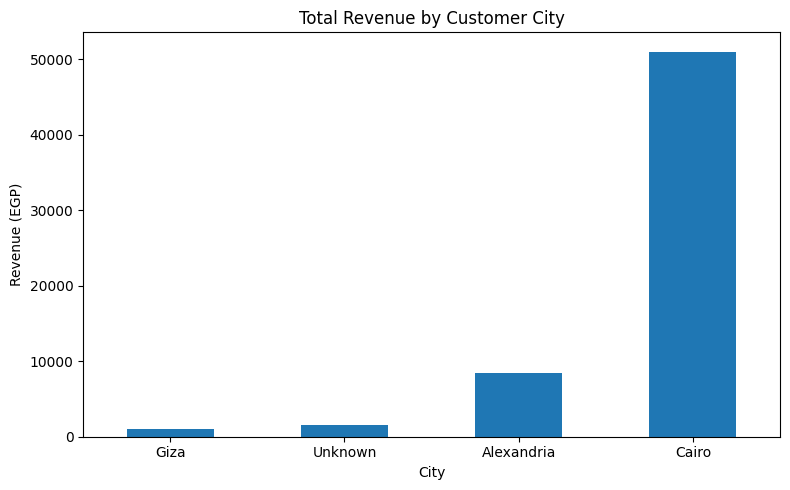

In [ ]:
city_performance["total_revenue"].sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Revenue by Customer City",
    xlabel="City",
    ylabel="Revenue (EGP)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Business Insights

### 1. Product Performance
- Laptops generated the highest revenue, contributing 45,000 EGP (approximately 72.5% of total revenue).
- Monitors ranked second, generating 12,000 EGP.
- Keyboards had the highest quantity sold, with 5 items, despite generating less revenue than laptops and monitors.

### 2. Category Performance
- Electronics generated 57,000 EGP, representing approximately 91.9% of total revenue.
- Accessories generated 5,050 EGP, accounting for approximately 8.1%.
- Electronics generated significantly higher revenue despite having fewer items sold.

### 3. Geographic Performance
- Cairo generated the highest revenue at 51,000 EGP (approximately 82.2%).
- Alexandria ranked second with 8,400 EGP.
- Some customer location data was missing, resulting in an Unknown category.

### 4. Payment Analysis
- Card payments accounted for 83.48% of total revenue.
- Cash payments contributed 6.85%.
- Payment method information was missing for one valid sales record.

### 5. Overall Sales Performance
- Total revenue reached 62,050 EGP across 10 valid orders.
- A total of 13 items were sold.
- Average Order Value (AOV) was 6,205 EGP.

## Business Recommendations

1. **Prioritize High-Revenue Products:** Maintain sufficient laptop inventory and monitor demand to avoid stock shortages.
2. **Review Product Mix:** Investigate opportunities to increase accessory revenue through product bundles and cross-selling.
3. **Focus on Key Markets:** Examine customer demand in Cairo while exploring opportunities to grow sales in Alexandria and Giza.
4. **Improve Data Collection:** Make customer city and payment method fields mandatory where appropriate.
5. **Monitor Data Quality:** Investigate negative prices and missing quantities before including affected records in financial reports.

## Project Limitations

- This project uses a small, simulated dataset created for demonstration purposes.
- Records with invalid prices or missing quantities were excluded from the sales analysis.
- Missing customer and payment information was categorized as Unknown.
- The dataset covers only January 2026, so it cannot establish long-term sales trends or seasonality.
- The findings should not be treated as conclusions about a real business.

In [ ]:
# Final project summary
print("PROJECT SUMMARY")
print("-" * 35)

print(f"Original Records: {len(df_raw)}")
print(f"Records After Deduplication: {len(df)}")
print(f"Valid Sales Records: {len(df_analysis)}")
print(f"Records Requiring Review: {len(missing_quantity)}")
print(f"Total Revenue: {total_revenue:,.2f} EGP")
print(f"Total Orders: {total_orders}")
print(f"Total Items Sold: {total_items}")
print(f"Average Order Value: {average_order_value:,.2f} EGP")

PROJECT SUMMARY
-----------------------------------
Original Records: 13
Records After Deduplication: 12
Valid Sales Records: 10
Records Requiring Review: 1
Total Revenue: 62,050.00 EGP
Total Orders: 10
Total Items Sold: 13.0
Average Order Value: 6,205.00 EGP
